<a href="https://colab.research.google.com/github/lilydavies442-lgtm/EP-stats-project-/blob/main/1.3_DataWrangling/1.3.11_TutorialExercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial Exercises

These tutorial exercises are designed to help you prepare for the first assignment.

As a researcher, there are two distinct phases to data analysis:

1) Understanding the dataset yourself - this involves making lots of quick plots and descriptive statistics to
    * check for outliers
    * find out the data distributions
    * look for differences between categories
    * look for associations between variables
<br>

2) Preparing a report for a reader - this involves a focus on readability and the reader
    * explain any key features of the dataset
    * highlighting key results with descriptive statistics and figures
    * figures should be well labelled and tweaked to make your point as clearly as possible
    * there should be clear, readable explanatory text
    * for most readers/clients, non technical language should be used
    * in all cases, jargon should be avoided

<hr style="border:0.5px solid #cccccc; margin: 10px 0;">

**In these tutorial exercises, you will complete some guided tasks (and some open-ended ones) to explore the dataset for yourself. For the hand-in assignment, you will produce a report on the same dataset for a specified reader.**

## Crime Survey Data

We will work with a dataset extracted from the Crime Survey England and Wales 2013.

I obtained the data from the UK Data Service, a data repository run by the UK Research Councils. This text is from their introduction to the dataset:

*The Crime Survey for England and Wales (CSEW) is a face-to-face victimisation survey in which
people resident in households in England and Wales are asked about their experiences of a range of
crimes in the 12 months prior to the interview. Respondents to the survey are also asked about their
perceptions of crime and attitudes towards crime related issues such as the police and criminal justice
system.*

The dataset I have given you contains only some of the questions that respondants were asked, containing information about the respondants' individual demographic features, neighbourhood, perceptions of crime and confidence in the police.

**The brief for the  hand-in report will be to write a short report for the Home Secretary addressing two topics:**
1. **Which groups are the most likely to be victims of crime? and**
2. **What factors affect confidence in policing?**

*Note that the idea is to write for a generic Home Secretary  - they have responsibility for Law and Order and as a politician are interested in how different sections of the public perceive these issues. You can assume they have no statistical training. However there is no need to accommodate the political attitudes or personal characteristics of any particular Home Secretary.*

In these preparatory exercises you will play around with the data to try and work out which factors are important predictors of that confidence.

I have put my own conclusions at the bottom of this page - this is just to give an idea of the kinds of things you might look at.


**Note:** *The survey was conducted in 2013 in the UK. Events of recent years may have affected the confidence of certain groups in the police; this would not be reflected in the data used here.*


### Set up Python libraries

In [2]:
# Set-up Python libraries - you need to run this but you don't need to change it
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import seaborn as sns
sns.set_theme(style='white')
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings
warnings.simplefilter('ignore', category=FutureWarning)

### Import the data

Download the dataset from Canvas and import them as a dataframe called `crime`

In [3]:
# WARNING! This will only work once you:
# download the datafile and
# put it in the right place on your computer!
crime  = pd.read_csv('CrimeData_2013.csv')
crime

,ID,Sex,Age,AgeGroup,EthnicGroup,Education,SES,DeprivationIndex,Victim,confpolice,antisoc
0,135230170.0,Male,45.0,4,White,University,2.0,3.0,0.0,-2.290506,-3.42
1,135230210.0,Male,28.0,2,White,University,1.0,4.0,0.0,0.349198,0.52
2,135231010.0,Female,58.0,5,Black or Black British,99,5.0,2.0,0.0,-0.381797,-2.27
3,135231210.0,Male,70.0,6,Asian or Asian British,GCSE,3.0,4.0,0.0,99.000000,99.00
4,135233210.0,Female,64.0,5,White,Other,5.0,5.0,0.0,0.613168,-0.84
...,...,...,...,...,...,...,...,...,...,...,...
9295,147638210.0,Male,43.0,3,White,University,1.0,99.0,0.0,1.029429,-0.31
9296,147639090.0,Male,70.0,6,White,99,5.0,99.0,0.0,-1.051876,0.45
9297,147639130.0,Female,80.0,7,White,99,5.0,99.0,0.0,-0.808211,-0.27
9298,147639250.0,Male,86.0,7,White,University,1.0,99.0,0.0,-1.711802,0.56


### Variables in the dataset

Information about the respondant and their neighbourhood:

* **ID** a unique number for each participant
* **Sex**
* **Age** in years
* **Age Group** ages in 10-year groups
* **Ethnic Group** the categories given are the ones recorded in the original survey
* **Education** highest level of education completed; modern British qualifications are used as a short hand for any equivalent, for example 'A-Levels' includes any equivalent of completing high school to age 18.
* **SES** socio-economic status
    * 1. Managerial and professional occs
    * 2. Intermediate occs
    * 3. Small employers and own account workers
    * 4. Lower supervisory and technical occupations
    * 5. Semi-routine and routine occupations
    * 6. Never worked and long term unemployed
    * 7. Full-time students
    * 8. Not classified
* **Deprivation Index** this is a neighbourhood-level measure of poverty, in qunitiles
    * 1 is the most deprived (poorest) 20% of neighbourhoods
    * 5 is the least deprived (wealthiest) 20%
* **Victim** has the respondant been a victim of crime in the last 12 months?


The following variables are **constructed** variables summarizing the respondant's attitudes on the following points:

* **confpolice** how confident are you in the policing of your neighbourhood?
* **antisoc** how much antisocial behaviour is there in your neighbourhood?
  
Each variable actually reflects a combination of the respondant's answers to several questions; for example **antisoc** is based on several questions asking about different antisocial behaviours- 'is there vandalism in your neighbourhood', 'are there gangs present in your neighbourhood', 'is there a fly tipping problem in your neighbourhood' etc):




## Check for bad values

Are there any outliers of filler values (such as `9999`) in the dataset?
* check, and deal with them appropriately

I would suggest starting with `df.describe()`

In [4]:
crime.describe()

,ID,Age,AgeGroup,SES,DeprivationIndex,Victim,confpolice,antisoc
count,9.300000e+03,9300.00000,9300.000000,9300.000000,9300.000000,9300.000000,9300.000000,9300.000000
mean,1.387841e+08,51.52828,4.155376,2.946559,10.769032,0.156022,6.589355,6.643392
std,4.422820e+06,18.81575,1.830384,1.852283,26.129501,0.362895,24.696669,24.788734
min,1.352302e+08,16.00000,1.000000,1.000000,1.000000,0.000000,-3.894633,-4.010000
25%,1.363271e+08,36.00000,3.000000,1.000000,2.000000,0.000000,-0.361492,-0.530000
50%,1.367402e+08,51.00000,4.000000,3.000000,3.000000,0.000000,0.156296,0.240000
75%,1.371590e+08,66.00000,6.000000,5.000000,5.000000,0.000000,0.663932,0.990000
max,1.476393e+08,99.00000,7.000000,8.000000,99.000000,1.000000,99.000000,99.000000


<Axes: xlabel='EthnicGroup', ylabel='count'>

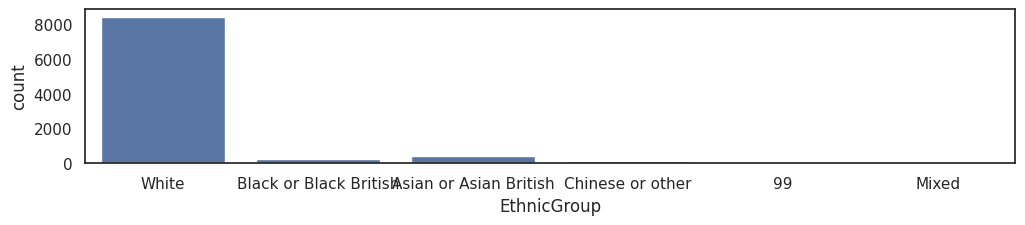

In [5]:
plt.figure(figsize=(12,2))
sns.countplot(data=crime, x='EthnicGroup')

In [6]:
crime.groupby('EthnicGroup').ID.count()

,ID
EthnicGroup,
99,13
Asian or Asian British,390
Black or Black British,255
Chinese or other,116
Mixed,81
White,8445


<Axes: xlabel='Age', ylabel='Density'>

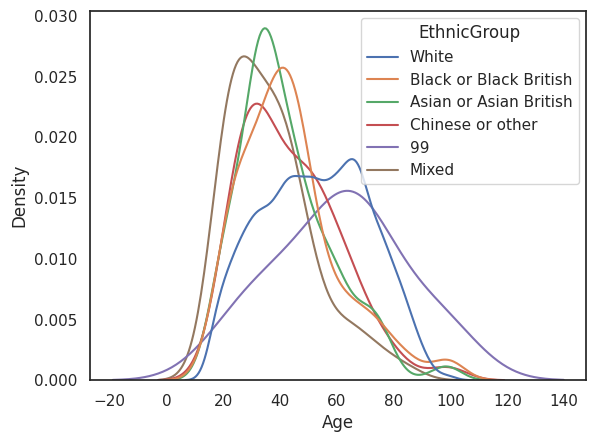

In [7]:
sns.kdeplot(data=crime, x='Age', hue='EthnicGroup', common_norm=False)


<Axes: xlabel='Age', ylabel='Count'>

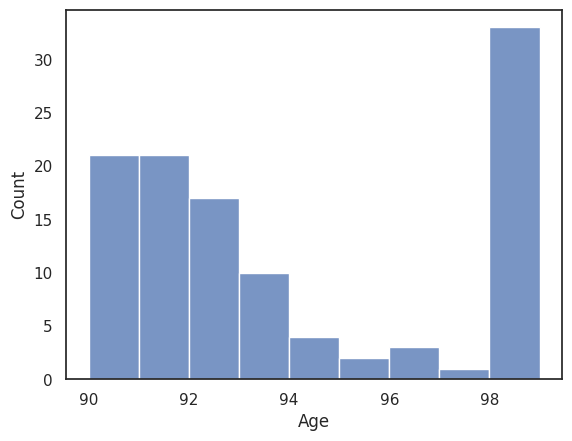

In [8]:
sns.histplot(data=crime, x="Age", bins=range(90,100,1))

In [9]:
crime.sort_values(by=['Age','AgeGroup']).tail(50)

,ID,Sex,Age,AgeGroup,EthnicGroup,Education,SES,DeprivationIndex,Victim,confpolice,antisoc
2108,136286050.0,Female,93.0,7,White,99,2.0,3.0,0.0,99.000000,99.00
2401,136341090.0,Female,93.0,7,White,99,2.0,2.0,0.0,0.613168,99.00
3529,136540170.0,Male,93.0,7,White,University,1.0,99.0,0.0,1.780729,1.22
3689,136570090.0,Male,93.0,7,White,99,4.0,5.0,0.0,0.359350,1.22
6772,137124170.0,Male,93.0,7,White,99,5.0,4.0,0.0,1.283247,99.00
7053,137172210.0,Female,93.0,7,White,99,4.0,3.0,0.0,-0.331034,0.74
8635,147484050.0,Female,93.0,7,White,99,1.0,3.0,0.0,99.000000,-0.28
1032,136098290.0,Female,94.0,7,White,99,6.0,5.0,0.0,1.080192,0.99
7365,137226170.0,Female,94.0,7,White,Other,5.0,99.0,0.0,0.856833,1.22
8658,147489090.0,Female,94.0,7,White,99,2.0,3.0,0.0,1.577675,-0.93


In [10]:
crime.groupby('AgeGroup').agg({'Age':['min','max']})

Age      
           min   max
AgeGroup            
1         16.0  24.0
2         25.0  99.0
3         35.0  99.0
4         45.0  99.0
5         55.0  99.0
6         65.0  99.0
7         75.0  99.0

In [11]:
crime.loc[(crime["Age"]==99)&(crime["AgeGroup"]!=7),"Age"]=np.nan
crime

,ID,Sex,Age,AgeGroup,EthnicGroup,Education,SES,DeprivationIndex,Victim,confpolice,antisoc
0,135230170.0,Male,45.0,4,White,University,2.0,3.0,0.0,-2.290506,-3.42
1,135230210.0,Male,28.0,2,White,University,1.0,4.0,0.0,0.349198,0.52
2,135231010.0,Female,58.0,5,Black or Black British,99,5.0,2.0,0.0,-0.381797,-2.27
3,135231210.0,Male,70.0,6,Asian or Asian British,GCSE,3.0,4.0,0.0,99.000000,99.00
4,135233210.0,Female,64.0,5,White,Other,5.0,5.0,0.0,0.613168,-0.84
...,...,...,...,...,...,...,...,...,...,...,...
9295,147638210.0,Male,43.0,3,White,University,1.0,99.0,0.0,1.029429,-0.31
9296,147639090.0,Male,70.0,6,White,99,5.0,99.0,0.0,-1.051876,0.45
9297,147639130.0,Female,80.0,7,White,99,5.0,99.0,0.0,-0.808211,-0.27
9298,147639250.0,Male,86.0,7,White,University,1.0,99.0,0.0,-1.711802,0.56


In [12]:
crime.sort_values(by=['Age','AgeGroup']).tail(32)

,ID,Sex,Age,AgeGroup,EthnicGroup,Education,SES,DeprivationIndex,Victim,confpolice,antisoc
5848,136952290.0,Male,98.0,7,White,99,3.0,99.0,0.0,99.000000,1.22
275,135532250.0,Male,99.0,7,White,99,3.0,5.0,0.0,99.000000,1.22
1149,136120210.0,Male,99.0,7,White,University,1.0,5.0,0.0,-0.564546,99.00
8098,147369290.0,Female,99.0,7,White,99,8.0,1.0,0.0,99.000000,99.00
103,135375010.0,Female,NaN,2,White,University,1.0,2.0,0.0,0.359350,-0.69
104,135375130.0,Male,NaN,2,White,ALevel,2.0,1.0,0.0,-1.386915,-0.74
1085,136108130.0,Female,NaN,2,White,University,2.0,2.0,0.0,99.000000,-1.02
2834,136416170.0,Female,NaN,2,White,Other,2.0,2.0,0.0,0.359350,-0.53
4380,136692170.0,Male,NaN,2,White,ALevel,3.0,2.0,0.0,0.613168,-0.23
5163,136830010.0,Male,NaN,2,Asian or Asian British,Other,6.0,1.0,0.0,-0.798058,-2.71


In [13]:
crime.groupby('AgeGroup').agg({'Age':['min','max']})

Age      
           min   max
AgeGroup            
1         16.0  24.0
2         25.0  34.0
3         35.0  44.0
4         45.0  54.0
5         55.0  64.0
6         65.0  74.0
7         75.0  99.0

### Have we got rid of all the 99's now?

We actually haven't. When we checked the dataframe using `df.describe()`, we only checked the numerical variables, but some of the variables coded as strings also have missing values coded as 99.

Have a look back at the dataframe and see if you can spot (and remove) them...

Let's check what string variables were in the dataframe:

In [14]:
crime.describe()

,ID,Age,AgeGroup,SES,DeprivationIndex,Victim,confpolice,antisoc
count,9.300000e+03,9272.000000,9300.000000,9300.000000,9300.000000,9300.000000,9300.000000,9300.000000
mean,1.387841e+08,51.384922,4.155376,2.946559,10.769032,0.156022,6.589355,6.643392
std,4.422820e+06,18.662127,1.830384,1.852283,26.129501,0.362895,24.696669,24.788734
min,1.352302e+08,16.000000,1.000000,1.000000,1.000000,0.000000,-3.894633,-4.010000
25%,1.363271e+08,36.000000,3.000000,1.000000,2.000000,0.000000,-0.361492,-0.530000
50%,1.367402e+08,51.000000,4.000000,3.000000,3.000000,0.000000,0.156296,0.240000
75%,1.371590e+08,66.000000,6.000000,5.000000,5.000000,0.000000,0.663932,0.990000
max,1.476393e+08,99.000000,7.000000,8.000000,99.000000,1.000000,99.000000,99.000000


Now we check whether there are any '99's using `df.column.unique()`:

In [15]:
crime.EthnicGroup.unique()

array(['White', 'Black or Black British', 'Asian or Asian British',
       'Chinese or other', '99', 'Mixed'], dtype=object)

Now we replace the 99's.

**Hint:** the 99's in these strong variables are the string '99', not the number `99`!

In [16]:
crime.EthnicGroup = crime.EthnicGroup.replace('99', 'No answer')
crime.Education = crime.Education.replace('99', 'No answer')
crime.DeprivationIndex =  crime.DeprivationIndex.replace(99, np.nan)
crime.confpolice = crime.confpolice.replace(99, np.nan)
crime.antisoc = crime.antisoc.replace(99, np.nan)
crime

,ID,Sex,Age,AgeGroup,EthnicGroup,Education,SES,DeprivationIndex,Victim,confpolice,antisoc
0,135230170.0,Male,45.0,4,White,University,2.0,3.0,0.0,-2.290506,-3.42
1,135230210.0,Male,28.0,2,White,University,1.0,4.0,0.0,0.349198,0.52
2,135231010.0,Female,58.0,5,Black or Black British,No answer,5.0,2.0,0.0,-0.381797,-2.27
3,135231210.0,Male,70.0,6,Asian or Asian British,GCSE,3.0,4.0,0.0,NaN,NaN
4,135233210.0,Female,64.0,5,White,Other,5.0,5.0,0.0,0.613168,-0.84
...,...,...,...,...,...,...,...,...,...,...,...
9295,147638210.0,Male,43.0,3,White,University,1.0,NaN,0.0,1.029429,-0.31
9296,147639090.0,Male,70.0,6,White,No answer,5.0,NaN,0.0,-1.051876,0.45
9297,147639130.0,Female,80.0,7,White,No answer,5.0,NaN,0.0,-0.808211,-0.27
9298,147639250.0,Male,86.0,7,White,University,1.0,NaN,0.0,-1.711802,0.56


## Explore the distribution of the variables

Now you will explore each variable individually by making suitable graphs. Complete each code block to produce a suitable plot or descriptive statistic. There are no right answers but in each case you should look at what you produced and evaluate whether your learned something from it!

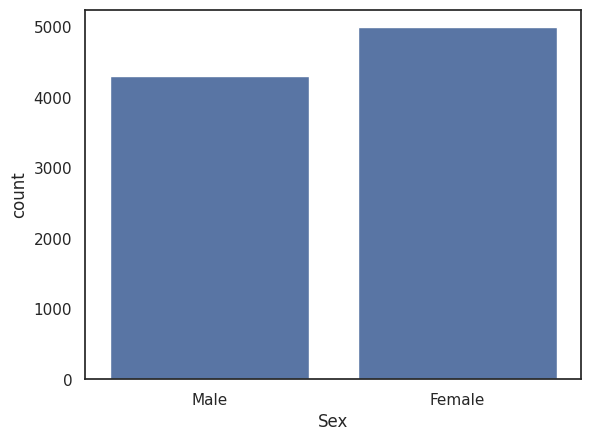

In [17]:
sns.countplot(data=crime, x='Sex')
plt.show()

<Axes: xlabel='Age', ylabel='Density'>

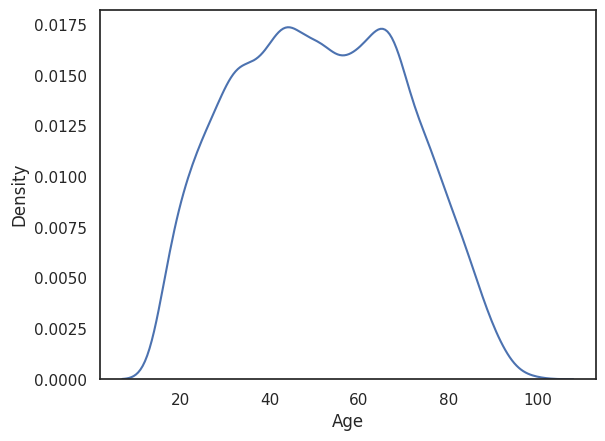

In [18]:
sns.kdeplot(data=crime, x='Age')

<Axes: xlabel='Age', ylabel='Count'>

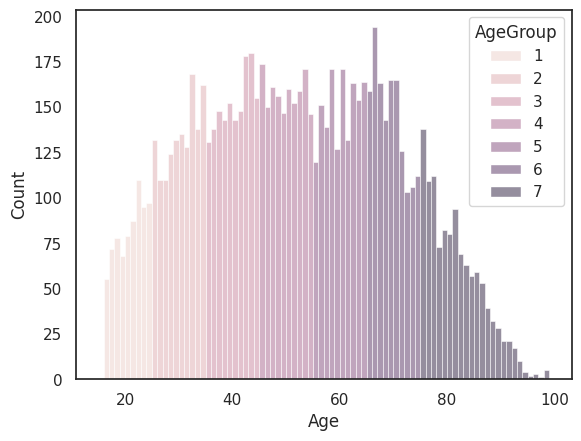

In [19]:
sns.histplot(data=crime, x='Age', hue="AgeGroup", bins=range(15,100,1))

<Axes: xlabel='EthnicGroup', ylabel='count'>

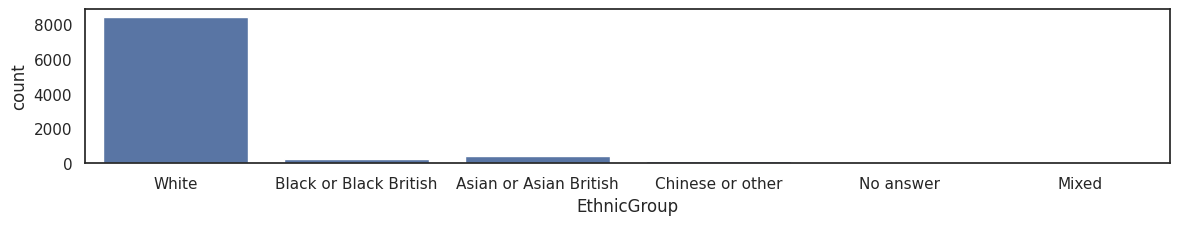

In [20]:
# How many respondants came from each ethnic group?
# Hint: you may need to resize the firgue so the x-axis labels are readable
# plt.figure(figsize=(12,2))
plt.figure(figsize=(14,2))
sns.countplot(data=crime, x='EthnicGroup')

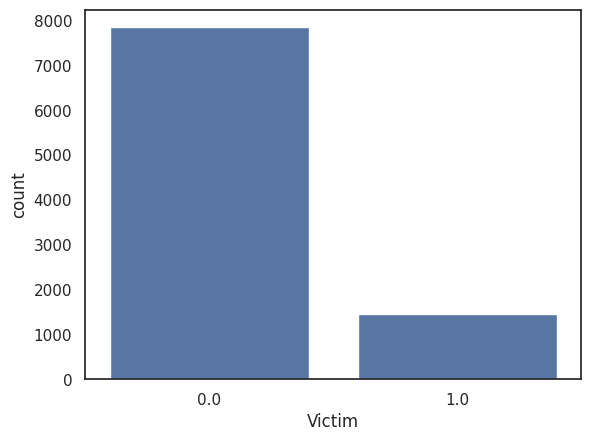

In [21]:
# What proportion of respondants have been a victim of crime in the last 12 months?
# Hint: `victim` is coded as 1 or 0
sns.countplot(data=crime, x='Victim')
plt.show()

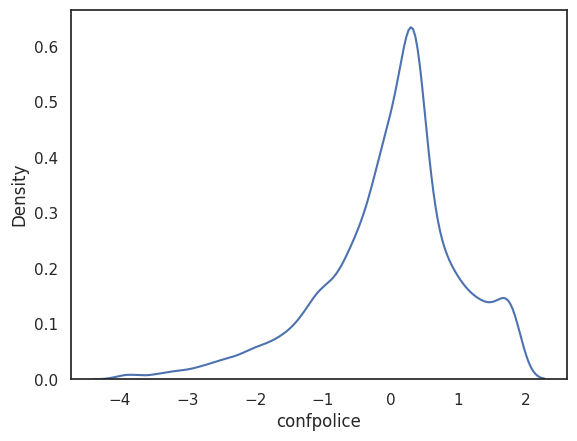

<Axes: xlabel='antisoc', ylabel='Density'>

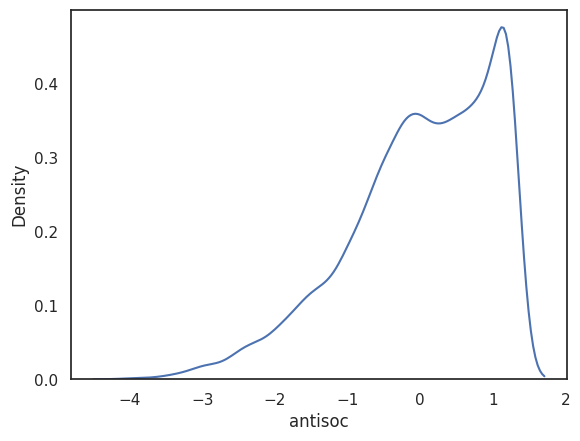

In [22]:
# For each of the constructed variables (confpolice and antisoc) plot the distribution
sns.kdeplot(x='confpolice', data=crime)
plt.show()
sns.kdeplot(x='antisoc', data=crime)

**NOTE -**
We note that these variables take positive and negative values

* For confidence in the police there is a strong spike around zero (many people have a neutral attitude - or are they disengaged or have no experience with the police? - later we will break this down by victims/non victims) - there is also a strong positive tail
* For perceptions of 'antisocial behaviour in my neighbourhood' there is a strong positive tail - could it depend on neighbourhood characteristics?


In [23]:
# Is there a correlation between people's experience of antisocial behaviour, and their confidence in the police?
crime.confpolice.corr(crime.antisoc)

np.float64(0.22781299372757596)

In [24]:
# For the attitude variables (confpolice and antisoc) what is the mean and standard deviation?
# Can you guess how these attitude variables ended up with that mean and standard deviation (think back to the section on standardizing data)?
crime.agg({'confpolice':['mean', 'std'], 'antisoc':['mean', 'std']})

,confpolice,antisoc
mean,-2.455510e-17,0.000870
std,1.000000e+00,1.000872


The means are 1 and the sd is 0 for each - they have been Z-scored.



In [25]:
# Which variables have a lot of missing data?
# HINT use df.isna() and sum()
crime.isna().sum()

,0
ID,0
Sex,0
Age,28
AgeGroup,0
EthnicGroup,0
Education,0
SES,0
DeprivationIndex,748
Victim,0
confpolice,619


## Who is most likely to be a victim of crime?

Explore which demographic variables make a difference to the chance of being a victim of crime. Are more men than women victims of crime? etc

**HINT** as `Victim` is coded as 1 (if they have been a victim of crime in the past 12 months) and 0 (otherwise), you can obtain the proportion of people who have been a victim by taking the mean value of the column `Victim`.

You can also use `sns.barplot()` with the `x` and `hue` arguments to plot the proportion who are victims of crime within each category (each age group, etc).


## Disaggregate the data

In the lecture we heard that a pattern that holds in one group of respondants may not hold for another group. We can check this by **disaggregating** the data.

#### Are students victims of crime because they live in deprived neighbourhoods?

Try plotting the proportion of people who are victime of crime broken down by deprivation index (as above), but further broken down by SES

**HINT:** Use the `hue` argument to get clusters of bars for each level of SES



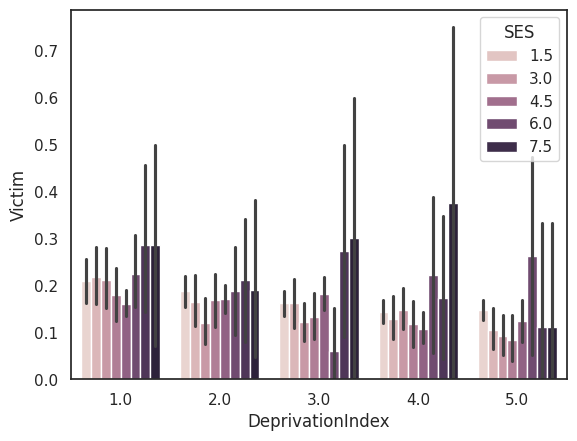

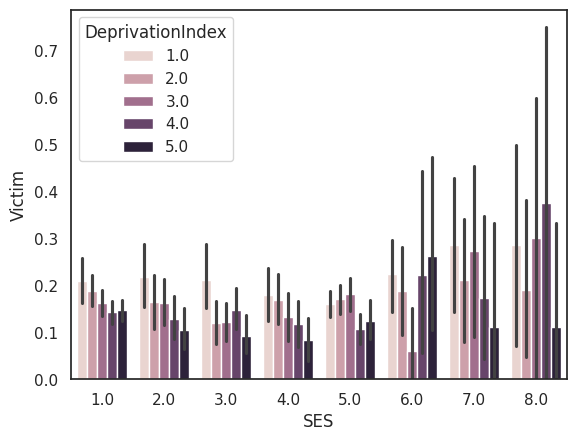

In [26]:
sns.barplot(data = crime, x='DeprivationIndex', y='Victim', hue='SES')
plt.show()
sns.barplot(data=crime, x='SES', y='Victim', hue='DeprivationIndex')
plt.show()

#### Do the patterns hold for all ethnicities?

The proportion of people who are victims of crime falls with age overall.

But is this true for all ethnicities?

The survey respondants were overwhelmingly white, so even if there was a quite different pattern of victimization in other ethnic groups, when we simply average everyone together this effect would be 'swamped'

Try plotting the proportion of people who are victims, broken down by `AgeGroup`, and further broken down by `EthinicGroup`

In [32]:

# Exploring victimisation across demographic groups

variables = [
    'Sex',
    'AgeGroup',
    'EthnicGroup',
    'Education',
    'SES',
    'DeprivationIndex'
]

for variable in variables:
    print(f"\nVictimisation by {variable}")

    results = crime.groupby(variable)['Victim'].agg(
        ['mean', 'count']
    )

    results['Percentage'] = results['mean'] * 100

    display(results[['count', 'Percentage']].round(2))



Victimisation by Sex


,count,Percentage
Sex,,
Female,4995,15.34
Male,4305,15.91



Victimisation by AgeGroup


,count,Percentage
AgeGroup,,
1,741,25.78
2,1349,20.76
3,1521,18.87
4,1583,16.49
5,1497,14.83
6,1437,10.16
7,1172,5.46



Victimisation by EthnicGroup


,count,Percentage
EthnicGroup,,
Asian or Asian British,390,17.44
Black or Black British,255,20.39
Chinese or other,116,9.48
Mixed,81,20.99
No answer,13,15.38
White,8445,15.41


... (2 outputs left out)


Victimisation by SES


,count,Percentage
SES,,
1.0,3496,16.13
2.0,954,15.30
3.0,1060,13.30
4.0,892,13.90
5.0,2416,15.48
6.0,276,19.57
7.0,133,24.06
8.0,73,21.92



Victimisation by DeprivationIndex


,count,Percentage
DeprivationIndex,,
1.0,1564,19.05
2.0,1684,17.16
3.0,1780,15.90
4.0,1792,13.50
5.0,1732,12.99


In [33]:
crime.groupby('AgeGroup')['Age'].agg(['min', 'max', 'count'])

,min,max,count
AgeGroup,,,
1,16.0,24.0,741
2,25.0,34.0,1339
3,35.0,44.0,1516
4,45.0,54.0,1576
5,55.0,64.0,1492
6,65.0,74.0,1436
7,75.0,99.0,1172


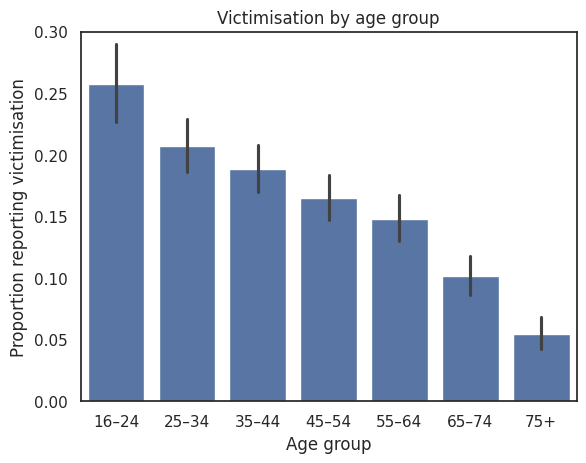

In [34]:
sns.barplot(data=crime, x='AgeGroup', y='Victim')

plt.xlabel('Age group')
plt.ylabel('Proportion reporting victimisation')
plt.title('Victimisation by age group')

plt.xticks(
    ticks=range(7),
    labels=['16–24', '25–34', '35–44', '45–54',
            '55–64', '65–74', '75+']
)

plt.ylim(0, 0.3)
plt.show()

## Do attitudes differ depending on demographics?

Looking at the attitude variables (`confpolice` and `antisoc`), which demographic factors seem to influence these?

I found it most helpful to make barplots for each attitude variable, broken down by demographic factors (such as deprivation index or age group).

Go ahead and explore the breakdown of `confpolice` and `antisoc` by `AgeGroup`, `EthnicGroup` and `DeprivationIndex`

### Age

In [28]:
# Your code here
# Hint: use plt.subplot to create pairs of plots - this keeps things tidy


## Deprivation Index

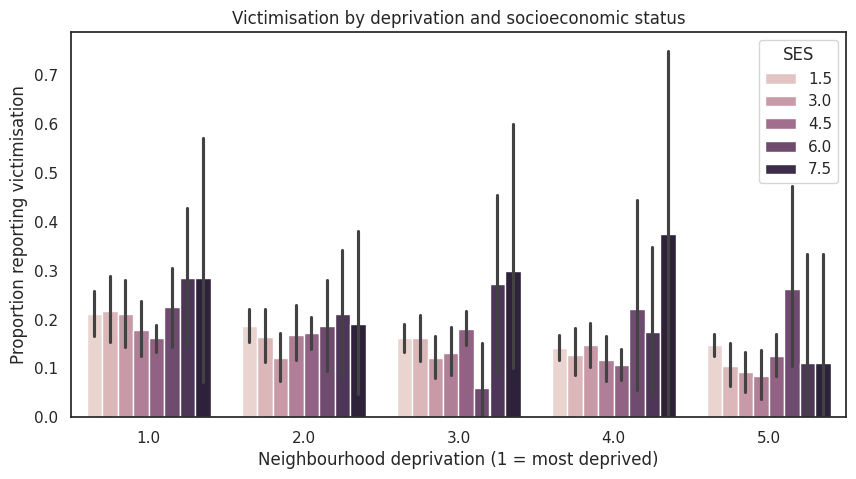

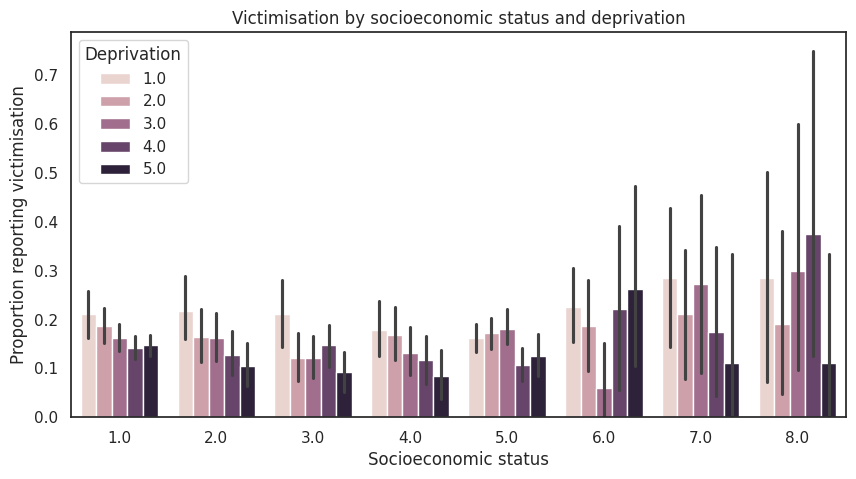

In [36]:
# Your code here
# Hint: use plt.subplot to create pairs of plots - this keeps things tidy
plt.figure(figsize=(10, 5))

sns.barplot(
    data=crime,
    x='DeprivationIndex',
    y='Victim',
    hue='SES'
)

plt.xlabel('Neighbourhood deprivation (1 = most deprived)')
plt.ylabel('Proportion reporting victimisation')
plt.title('Victimisation by deprivation and socioeconomic status')
plt.legend(title='SES')
plt.show()


plt.figure(figsize=(10, 5))

sns.barplot(
    data=crime,
    x='SES',
    y='Victim',
    hue='DeprivationIndex'
)

plt.xlabel('Socioeconomic status')
plt.ylabel('Proportion reporting victimisation')
plt.title('Victimisation by socioeconomic status and deprivation')
plt.legend(title='Deprivation')
plt.show()

## Ethnic Group

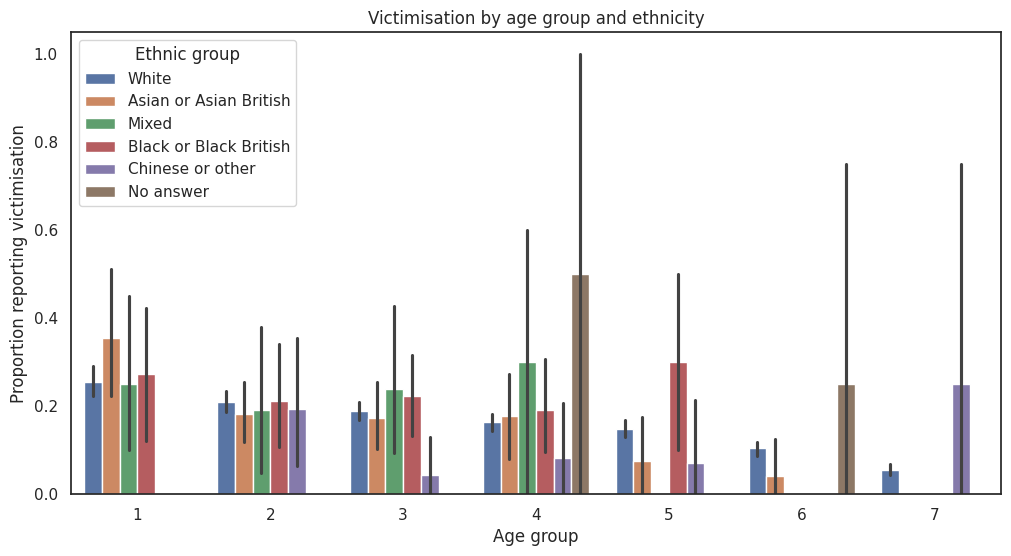

In [37]:
# Your code here
# Hint: use plt.subplot to create pairs of plots - this keeps things tidy
plt.figure(figsize=(12, 6))

sns.barplot(
    data=crime,
    x='AgeGroup',
    y='Victim',
    hue='EthnicGroup'
)

plt.xlabel('Age group')
plt.ylabel('Proportion reporting victimisation')
plt.title('Victimisation by age group and ethnicity')
plt.legend(title='Ethnic group')
plt.show()

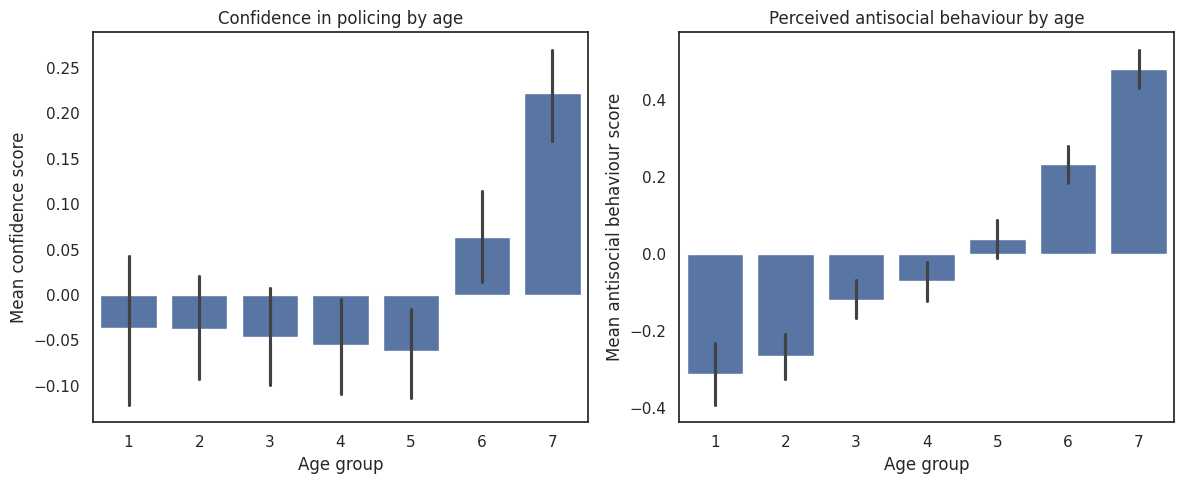

In [38]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.barplot(data=crime, x='AgeGroup', y='confpolice')
plt.xlabel('Age group')
plt.ylabel('Mean confidence score')
plt.title('Confidence in policing by age')

plt.subplot(1, 2, 2)
sns.barplot(data=crime, x='AgeGroup', y='antisoc')
plt.xlabel('Age group')
plt.ylabel('Mean antisocial behaviour score')
plt.title('Perceived antisocial behaviour by age')

plt.tight_layout()
plt.show()

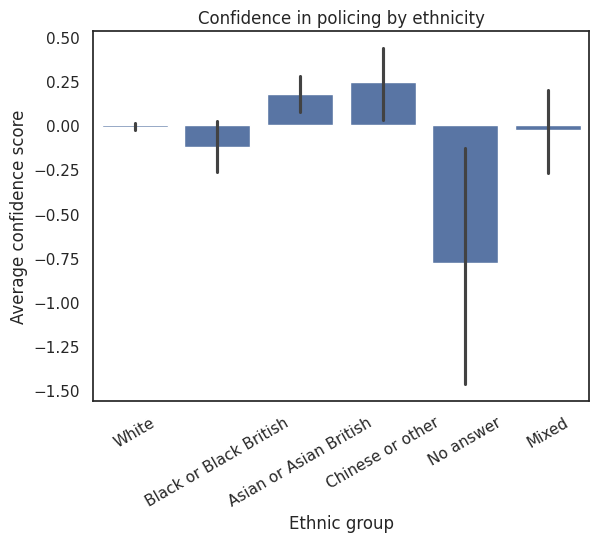

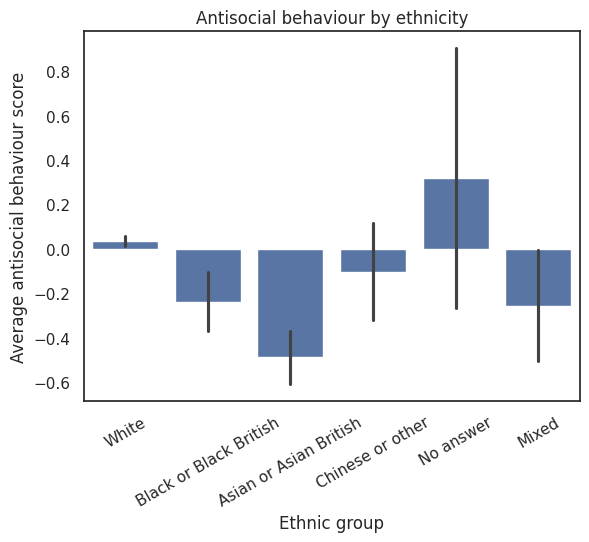

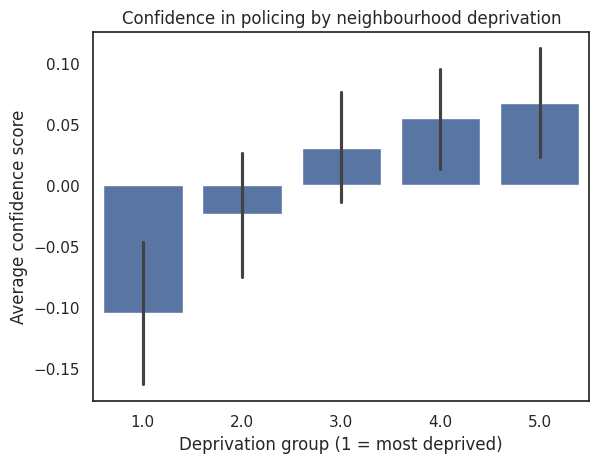

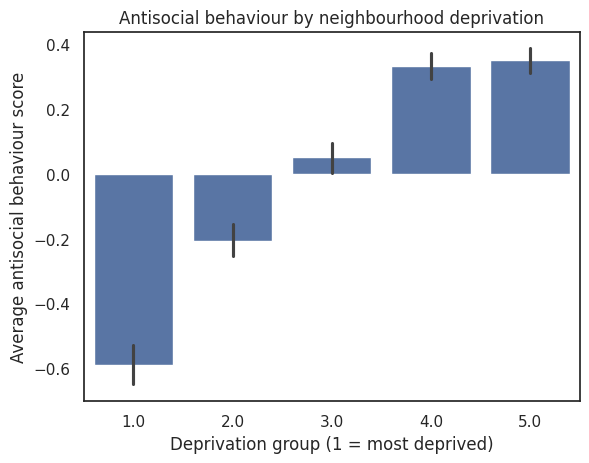

In [39]:
# Confidence in policing by ethnicity
sns.barplot(data=crime, x='EthnicGroup', y='confpolice')
plt.title('Confidence in policing by ethnicity')
plt.xlabel('Ethnic group')
plt.ylabel('Average confidence score')
plt.xticks(rotation=30)
plt.show()

# Antisocial behaviour by ethnicity
sns.barplot(data=crime, x='EthnicGroup', y='antisoc')
plt.title('Antisocial behaviour by ethnicity')
plt.xlabel('Ethnic group')
plt.ylabel('Average antisocial behaviour score')
plt.xticks(rotation=30)
plt.show()

# Confidence in policing by deprivation
sns.barplot(data=crime, x='DeprivationIndex', y='confpolice')
plt.title('Confidence in policing by neighbourhood deprivation')
plt.xlabel('Deprivation group (1 = most deprived)')
plt.ylabel('Average confidence score')
plt.show()

# Antisocial behaviour by deprivation
sns.barplot(data=crime, x='DeprivationIndex', y='antisoc')
plt.title('Antisocial behaviour by neighbourhood deprivation')
plt.xlabel('Deprivation group (1 = most deprived)')
plt.ylabel('Average antisocial behaviour score')
plt.show()

In [40]:
crime['confpolice'].corr(crime['antisoc'])

np.float64(0.22781299372757596)

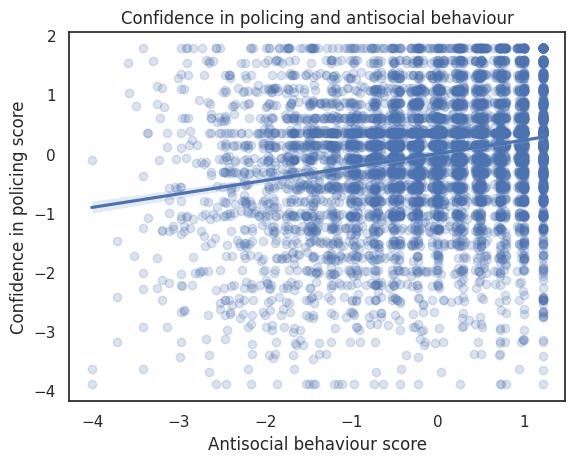

In [41]:
sns.regplot(data=crime, x='antisoc', y='confpolice',
            scatter_kws={'alpha': 0.2})

plt.title('Confidence in policing and antisocial behaviour')
plt.xlabel('Antisocial behaviour score')
plt.ylabel('Confidence in policing score')
plt.show()

In [42]:
age_results = crime.groupby('AgeGroup').agg(
    count=('confpolice', 'count'),
    confidence=('confpolice', 'mean'),
    antisocial=('antisoc', 'mean')
)

display(age_results.round(2))

,count,confidence,antisocial
AgeGroup,,,
1,724,-0.04,-0.31
2,1294,-0.04,-0.26
3,1433,-0.05,-0.12
4,1495,-0.06,-0.07
5,1401,-0.06,0.04
6,1309,0.06,0.23
7,1025,0.22,0.48


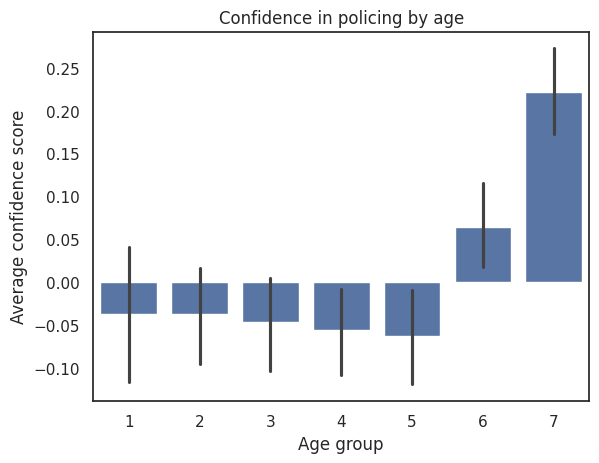

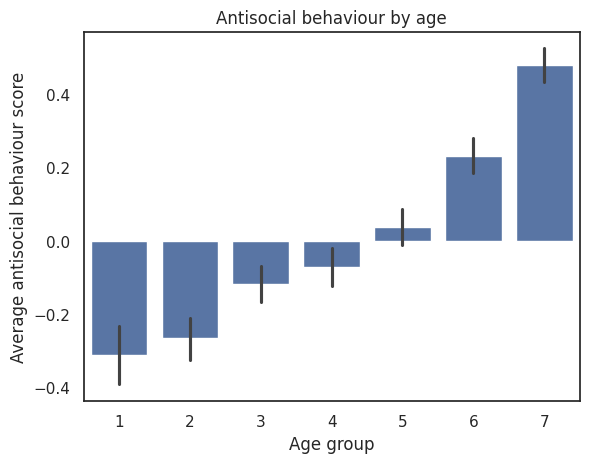

In [43]:
sns.barplot(data=crime, x='AgeGroup', y='confpolice')
plt.title('Confidence in policing by age')
plt.xlabel('Age group')
plt.ylabel('Average confidence score')
plt.show()

sns.barplot(data=crime, x='AgeGroup', y='antisoc')
plt.title('Antisocial behaviour by age')
plt.xlabel('Age group')
plt.ylabel('Average antisocial behaviour score')
plt.show()

In [44]:
crime.groupby('DeprivationIndex')['confpolice'].mean().round(2)

,confpolice
DeprivationIndex,
1.0,-0.10
2.0,-0.02
3.0,0.03
4.0,0.05
5.0,0.07


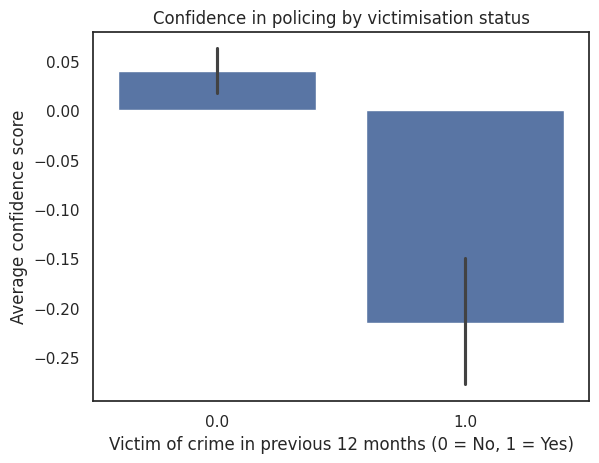

In [45]:
sns.barplot(data=crime, x='Victim', y='confpolice')

plt.title('Confidence in policing by victimisation status')
plt.xlabel('Victim of crime in previous 12 months (0 = No, 1 = Yes)')
plt.ylabel('Average confidence score')
plt.show()

In [46]:
crime.groupby('Victim')['confpolice'].agg(['mean', 'count']).round(2)

,mean,count
Victim,,
0.0,0.04,7319
1.0,-0.22,1362


In [47]:
crime[['Victim', 'AgeGroup', 'EthnicGroup', 'SES',
       'DeprivationIndex', 'confpolice', 'antisoc']].isna().sum()

,0
Victim,0
AgeGroup,0
EthnicGroup,0
SES,0
DeprivationIndex,748
confpolice,619
antisoc,624


## Lurking Variables?

Earlier we noticed that people who reported higher levels of antisocial behaviour in their neighbourhood also had higher confidence in the police, which is somewhat surprising.

Looking at how `confpolice` and `antisoc` vary by `AgeGroup`, can you think of a spurious explanation for this correlation?

## Conclusions

Now think about how you might summarize what you have learned from the dataset

* who is most likely to be a victim of crime?
* who is most likely to report high levels of antisocial behaviour in their neighbourhood?
* what factors predict confidence in the police and experience of antisocial behaviour?
* what are the limitations of the survey? Are the experiences of all groups equally well documented?

In [31]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
